# Image inference

Use the PanopTILs model from [training](training.ipynb) to find nuclei and
cell types in a validation image. Each instance label identifies one nucleus;
a class label gives its type. Compare predictions with the dataset labels,
then save the predicted masks.

Complete [data preparation](prepare-data.ipynb) and training first. This example
uses their data and saved model. For public pretrained weights, use
the csmp-hub loading example below.


## Setup


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.patches import Patch
from safetensors import safe_open
from skimage.color import label2rgb

from cellseg_models_pytorch.inference.post_processor import PostProcessor
from cellseg_models_pytorch.metrics import panoptic_quality
from cellseg_models_pytorch.models.cellpose import CellPose
from cellseg_models_pytorch.transforms.functional.normalization import minmax_normalize
from cellseg_models_pytorch.utils import FileHandler


# Prefer CUDA, using the same device choice as the training example.
torch.set_num_threads(2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

data_root = Path("../../data/panoptils-nuclei")
checkpoint_path = Path("training-checkpoints/epoch_05/model.safetensors")


Device: cuda


## Load a csmp-hub model

To use pretrained weights without training a model, load the
[HGSC CellPose checkpoint](https://huggingface.co/csmp-hub/cellpose-histo-hgsc-nuc-v1)
by its registered name. The weights download on first use.

```python
pretrained_model = CellPose.from_pretrained("hgsc_v1_efficientnet_b5", device=device)
pretrained_model.set_inference_mode(mixed_precision=False)
```

Use the preprocessing and cell-type mapping in the model card. These classes differ
from PanopTILs. The walkthrough below uses the locally trained PanopTILs `model`.


## Load the trained model


In [2]:
# Read the cell-type meanings stored alongside the trained weights.
with safe_open(checkpoint_path, framework="pt", device="cpu") as weights:
    class_names = json.loads(weights.metadata()["class_names"])

model = CellPose.from_pretrained(checkpoint_path, device=device)

# Keep full precision to match the training example’s validation.
model.set_inference_mode(mixed_precision=False)

# Reconstruct nucleus instances from the predicted CellPose flows.
model.post_processor = PostProcessor("cellpose", {"use_gpu": device.type == "cuda"})


## Load a validation image


In [3]:
# Keep the validation image at its original size.
image_path = sorted((data_root / "validation/regions/images").glob("*.png"))[0]
raw_image = FileHandler.read_img(image_path)
labels = FileHandler.read_mat(
    data_root / "validation/regions/labels" / f"{image_path.stem}.mat"
)

# Match the global min-max normalization used for training.
image = minmax_normalize(raw_image, copy=True)


## Predict nuclei and cell types


In [4]:
# Predict dense maps, then reconstruct nuclei and assign their cell types.
prediction = model.predict(image)
result = model.post_process(prediction, use_async_postproc=False)

# The nucleus branch returns one instance/type-mask pair per input image.
instances, classes = result["nuc"][0]

print("Predicted nuclei:", len(np.unique(instances[instances > 0])))
print("Instance PQ:", round(panoptic_quality(labels["inst"], instances)["pq"], 3))


Predicted nuclei: 623


Instance PQ: 0.686


## Compare the masks

Compare the same tissue image with its labels and predictions. Panoptic quality
(PQ) measures nucleus matching and overlap; 1 is perfect. This score describes one
image. The training example checks 16 validation images.

The legend identifies tumour (neoplastic), supporting tissue (stromal) and immune
(inflammatory) cells. “Unknown” means the dataset did not assign a specific type.
Brown nuclei were assigned class 0; black is background with no nucleus.


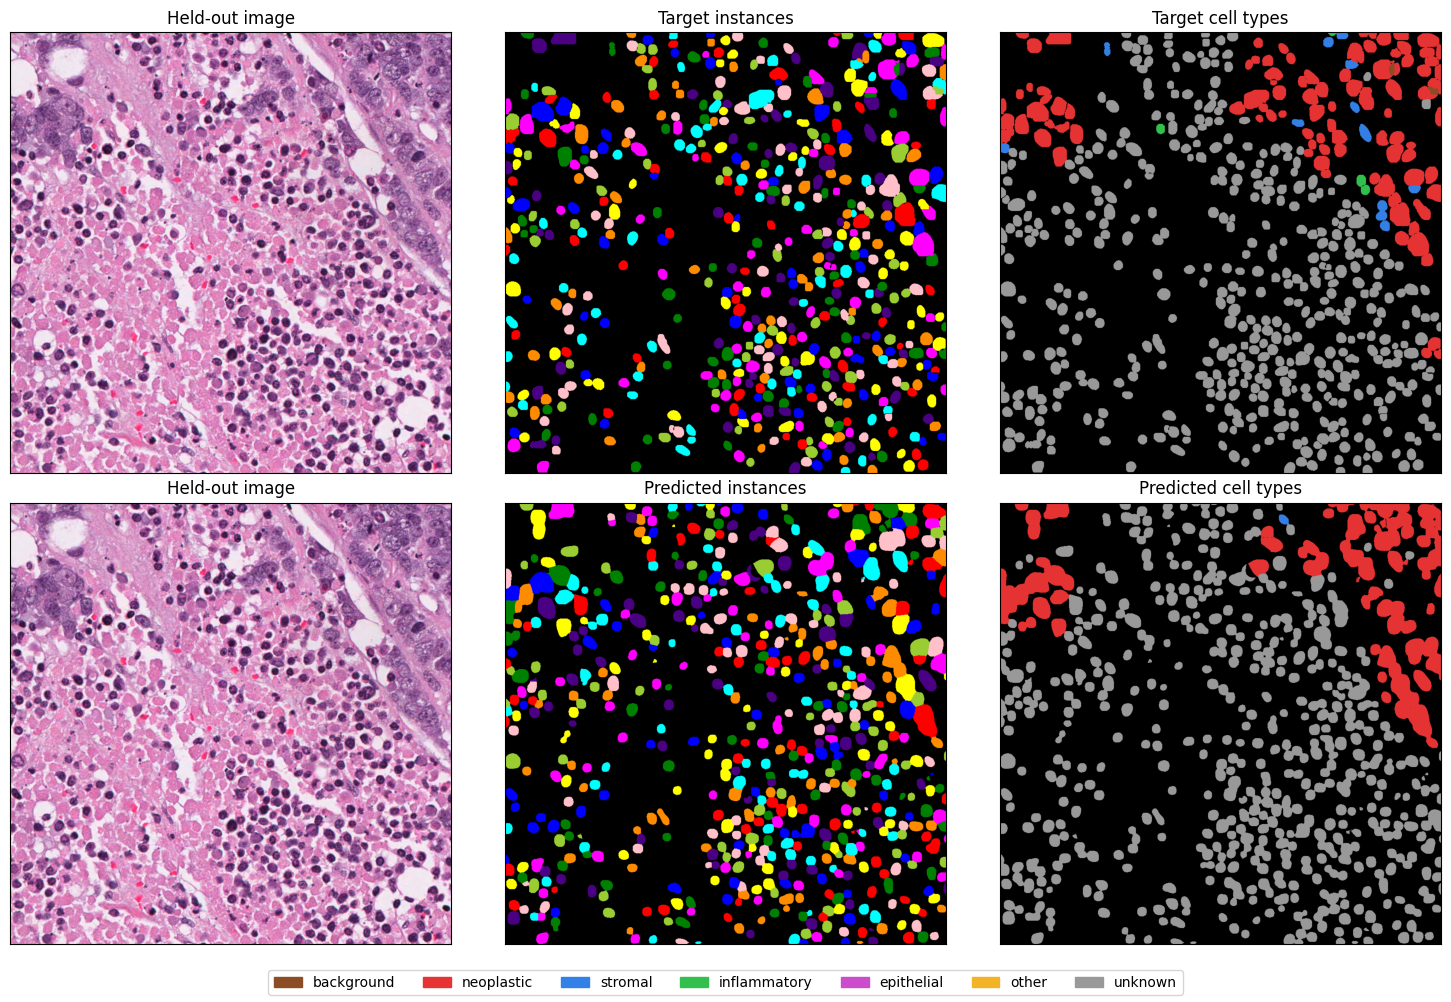

In [5]:
# Use the same class colours for targets and predictions.
class_palette = np.array(
    [
        [0.55, 0.3, 0.15],
        [0.9, 0.2, 0.2],
        [0.2, 0.5, 0.9],
        [0.2, 0.75, 0.3],
        [0.8, 0.3, 0.8],
        [0.95, 0.7, 0.15],
        [0.6, 0.6, 0.6],
    ]
)

# Instance colours distinguish individual nuclei, regardless of cell type.
instance_colors = label2rgb(instances, bg_label=0)

# Instance masks distinguish background from nuclei assigned class 0.
class_colors = class_palette[classes]
class_colors[instances == 0] = 0

target_class_colors = class_palette[labels["type"].astype(int)]
target_class_colors[labels["inst"] == 0] = 0

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Top row: the validation image and its ground-truth masks.
axes[0, 0].imshow(raw_image)
axes[0, 0].set_title("Held-out image")

axes[0, 1].imshow(label2rgb(labels["inst"], bg_label=0))
axes[0, 1].set_title("Target instances")

axes[0, 2].imshow(target_class_colors)
axes[0, 2].set_title("Target cell types")

# Bottom row: the same image and the model’s predictions.
axes[1, 0].imshow(raw_image)
axes[1, 0].set_title("Held-out image")

axes[1, 1].imshow(instance_colors)
axes[1, 1].set_title("Predicted instances")

axes[1, 2].imshow(class_colors)
axes[1, 2].set_title("Predicted cell types")

for axis in axes.flat:
    axis.set(xticks=[], yticks=[])

fig.legend(
    [Patch(color=colour) for colour in class_palette],
    class_names,
    loc="lower center",
    ncol=7,
)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()


## Predict with sliding windows

Run overlapping windows over the same image already in memory, without resizing
it. Here, 256-pixel windows with a stride of 128 give 50% overlap. The inferer
combines the dense maps before reconstructing nuclei, keeping the masks aligned
with the original image.

Windows limit each model forward pass. The full image and combined maps still
occupy device memory; use the [WSI example](wsi.ipynb) for whole slides.


In [6]:
# Reuse the image normalized above; do not normalize individual windows.
sliding_prediction = model.predict(
    image,
    use_sliding_win=True,
    window_size=(256, 256),
    stride=128,
)

sliding_result = model.post_process(sliding_prediction, use_async_postproc=False)
sliding_instances, sliding_classes = sliding_result["nuc"][0]


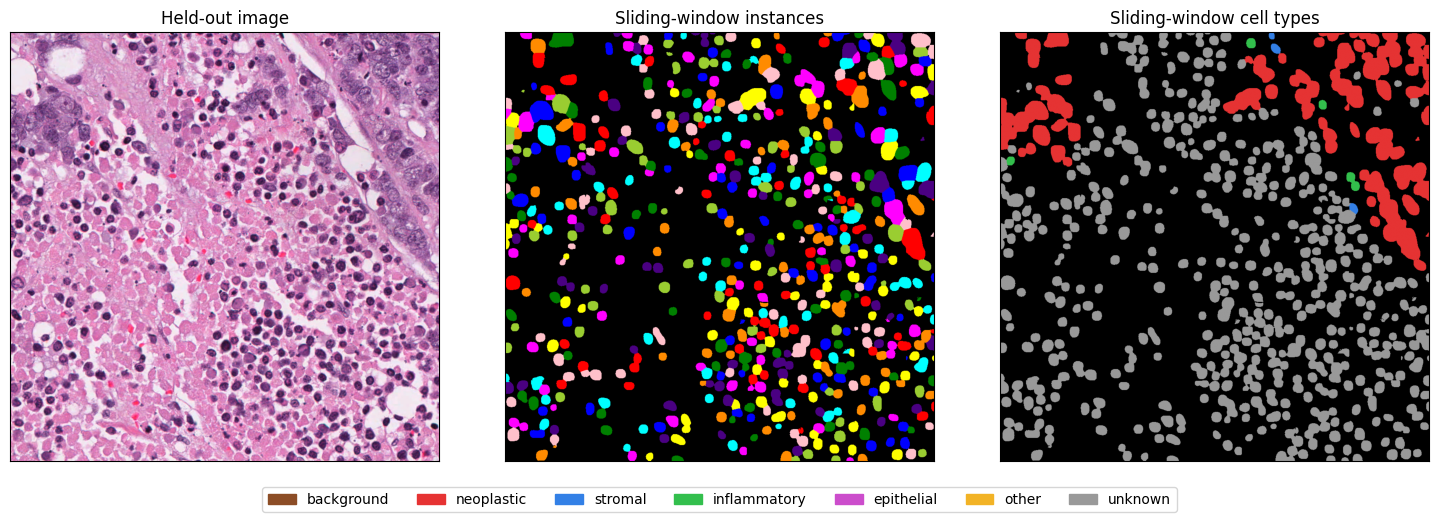

In [7]:
# Keep the same class colours and distinguish class 0 nuclei from background.
sliding_class_colors = class_palette[sliding_classes]
sliding_class_colors[sliding_instances == 0] = 0

sliding_fig, sliding_axes = plt.subplots(1, 3, figsize=(15, 5))

sliding_axes[0].imshow(raw_image)
sliding_axes[0].set_title("Held-out image")

sliding_axes[1].imshow(label2rgb(sliding_instances, bg_label=0))
sliding_axes[1].set_title("Sliding-window instances")

sliding_axes[2].imshow(sliding_class_colors)
sliding_axes[2].set_title("Sliding-window cell types")

for axis in sliding_axes:
    axis.set(xticks=[], yticks=[])

sliding_fig.legend(
    [Patch(color=colour) for colour in class_palette],
    class_names,
    loc="lower center",
    ncol=7,
)
sliding_fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()


## Save the masks

Set `output_path`, then uncomment the save block to store both masks in a NumPy
`.npz` file. Integer labels preserve nucleus IDs: zero is background and each
positive number identifies one nucleus. Cell-type IDs keep the meanings shown
in the legend.


In [8]:
output_path = Path("segmentation.npz")
# Choose a filename, then uncomment to save both masks.
# with output_path.open("xb") as output:
#     np.savez_compressed(output, instances=instances, classes=classes)
